# Carbon Bombs: Potential Exposure to Climatic Extremes Induced by the Largest Fossil Fuel Projects

## Purpose of this notebook

Carbon bombs are the 425 largest fossil fuel extraction projects in the world, each able to emit at least 1 GtCO₂ if its reserves are fully extracted and burned [1]. The 2025 update of the database [2] gives a combined potential of about 924 GtCO₂, far more than the remaining 1.5 °C carbon budget (130 GtCO₂) [2]. The largest single project, the **Permian Delaware Tight** shale oil and gas field (Texas, USA), still contains about 23 GtCO₂.

This notebook is a step-by-step tutorial that:

1. reads and cleans the updated carbon bomb database and stores it as an `xarray.Dataset` (`ds_carbon_bombs`);
2. visualises the potential emissions of the carbon bombs (20 largest projects, by country, by fuel type);
3. loads the projections of the number of people, per country and per region, who will experience at least one additional climate extreme (heatwaves, droughts, crop failures, river floods, wildfires, tropical cyclones) over their lifetime because of the CO₂ emissions of the Permian Delaware Tight carbon bomb [2, 5];
4. maps these results for children born in 2025, and compares birth cohorts to highlight the intergenerational inequity in exposure.

## References

[1] Kühne, K., Bartsch, N., Driskell Tate, R., Higson, J., & Habet, A. (2022). "Carbon Bombs" – Mapping key fossil fuel projects. *Energy Policy*, 166, 112950.
[2] Laridon, A., Pietroiusti, R., Smith, C., et al. (2026, in prep.). A framework linking project-level greenhouse gas emissions to additional climate extremes exposure and multi-century committed change.
[3] Global Carbon Budget 2025. *Earth System Science Data*, 18(5).
[4] Abram, N. J., et al. (2025). Quantifying the regional to global climate impacts of individual fossil fuel projects to inform decision-making. *npj Climate Action*, 4(1), 92.
[5] Grant, L., Vanderkelen, I., Gudmundsson, L., Fischer, E., Seneviratne, S. I., & Thiery, W. (2025). Global emergence of unprecedented lifetime exposure to climate extremes. *Nature*, 641, 374–379.

## 0. Modules and paths

In [1]:
# --- Modules -------------------------------------------------------------
from pathlib import Path          # operating-system independent file paths
import pickle                     # read / write .pkl files
import textwrap                   # wrap long project names on several lines

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.patches import Patch   # custom legend entries
import geopandas as gpd

In [2]:
# --- Paths ---------------------------------------------------------------
# The notebook lives in notebooks/, the data in data/ and the figures in figures/.
# Using Path objects (and no hard-coded C:\Users\... paths) makes the notebook
# run on every team member's computer, on Windows, macOS and Linux.
PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = PROJECT_DIR / "data"
FIG_DIR = PROJECT_DIR / "figures"

# Input files 
FILE_DS_CB = DATA_DIR / "ds_carbon_bombs.pkl"    # output of Task 4, input of Task 5

print("Data folder:", DATA_DIR, "| exists:", DATA_DIR.exists())

Data folder: c:\Users\user\Downloads\CARBON-BOMB-PINGPONG-GROUP\data | exists: True


## 1. The 20 largest carbon bombs (Task 5)

`plot_top_carbon_bombs()` draws the potential emissions of the largest carbon bombs from the `ds_carbon_bombs` dataset:
- one bar per project, from largest to smallest (best estimate), with the project name on the x-axis;
- the **colour** shows the country (`country` coordinate);
- the **hatching** shows the fuel type (`fuel` coordinate): hatched = coal, plain = oil & gas;
- the **error bars** go from the low (P2.5) to the high (P97.5) estimate.

The dataset is read from the pickle saved in Task 4, so this section also runs on its own.

In [3]:
# Load ds_carbon_bombs from the pickle produced in Task 4
with open(FILE_DS_CB, "rb") as f:
    ds_carbon_bombs = pickle.load(f)

In [4]:
def plot_top_carbon_bombs(ds, n_top=20, save_path=None):
    """Bar plot of the potential emissions of the n_top largest carbon bombs (Task 5).

    - one bar per project, sorted from largest to smallest (best estimate)
    - bar colour  = country of the project (one colour per country)
    - hatching    = fuel type (hatched = coal, plain = oil & gas)
    - error bars  = low (P2.5) to high (P97.5) estimate

    Parameters
    ----------
    ds : xarray.Dataset
        the ds_carbon_bombs dataset (dimension 'name', coordinates 'country' and
        'fuel', variable 'potential_emissions' with estimate = best/low/high)
    n_top : int
        number of projects to show (default 20)
    save_path : str or Path, optional
        if given, the figure is saved there as a high-resolution PNG
    """
    # 1. Select the n_top largest projects, sorted on the best estimate
    best_all = ds["potential_emissions"].sel(estimate="best")
    top = ds.sortby(best_all, ascending=False).isel(name=slice(0, n_top))

    best = top["potential_emissions"].sel(estimate="best").values
    low = top["potential_emissions"].sel(estimate="low").values
    high = top["potential_emissions"].sel(estimate="high").values
    countries = top["country"].values
    fuels = top["fuel"].values
    names = top["name"].values

    # 2. One colour per country (order of first appearance = largest project first)
    country_list = list(dict.fromkeys(countries))
    # tab20 holds 10 hues, each in a dark and a light shade: we first use the 10 dark
    # shades (indices 0, 2, 4, ...) and only then the light ones, so that neighbouring
    # countries get clearly different hues
    cmap = plt.get_cmap("tab20")
    order = list(range(0, 20, 2)) + list(range(1, 20, 2))
    country_colour = {c: cmap(order[i % 20]) for i, c in enumerate(country_list)}

    # 3. Error bars: matplotlib wants the distances below and above the bar
    yerr = np.array([best - low, high - best])

    # 4. Draw the bars
    fig, ax = plt.subplots(figsize=(14, 6.5))
    x = np.arange(n_top)
    bars = ax.bar(x, best,
                  color=[country_colour[c] for c in countries],
                  edgecolor="black", linewidth=0.6,
                  yerr=yerr, capsize=3, error_kw={"elinewidth": 1, "ecolor": "black"})
    for bar, fuel in zip(bars, fuels):
        if fuel == "Coal":
            bar.set_hatch("///")

    # 5. Axes, labels and title
    wrapped = [textwrap.fill(name, 22) for name in names]  # break long names on 2 lines
    ax.set_xticks(x)
    ax.set_xticklabels(wrapped, rotation=55, ha="right", rotation_mode="anchor", fontsize=8.5)
    ax.set_ylabel("Potential CO$_2$ emissions [GtCO$_2$]")
    ax.set_title(f"The {n_top} largest carbon bombs: potential CO$_2$ emissions in 2025\n"
                 "(error bars: 95 % range, P2.5–P97.5)")
    ax.grid(axis="y", color="0.85", linewidth=0.8)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)

    # 6. Two legends: countries (colours) and fuel types (hatching)
    country_handles = [Patch(facecolor=country_colour[c], edgecolor="black", label=c)
                       for c in country_list]
    fuel_handles = [Patch(facecolor="white", edgecolor="black", label="Oil & gas"),
                    Patch(facecolor="white", edgecolor="black", hatch="///", label="Coal")]
    legend_country = ax.legend(handles=country_handles, title="Country",
                               loc="upper right", ncol=2, fontsize=8.5, frameon=False)
    ax.add_artist(legend_country)  # keep the first legend when adding the second one
    ax.legend(handles=fuel_handles, title="Fuel", loc="center right",
              bbox_to_anchor=(1.0, 0.45), fontsize=8.5, frameon=False)

    fig.tight_layout()
    if save_path is not None:
        fig.savefig(save_path, dpi=300, bbox_inches="tight")
    return fig, ax

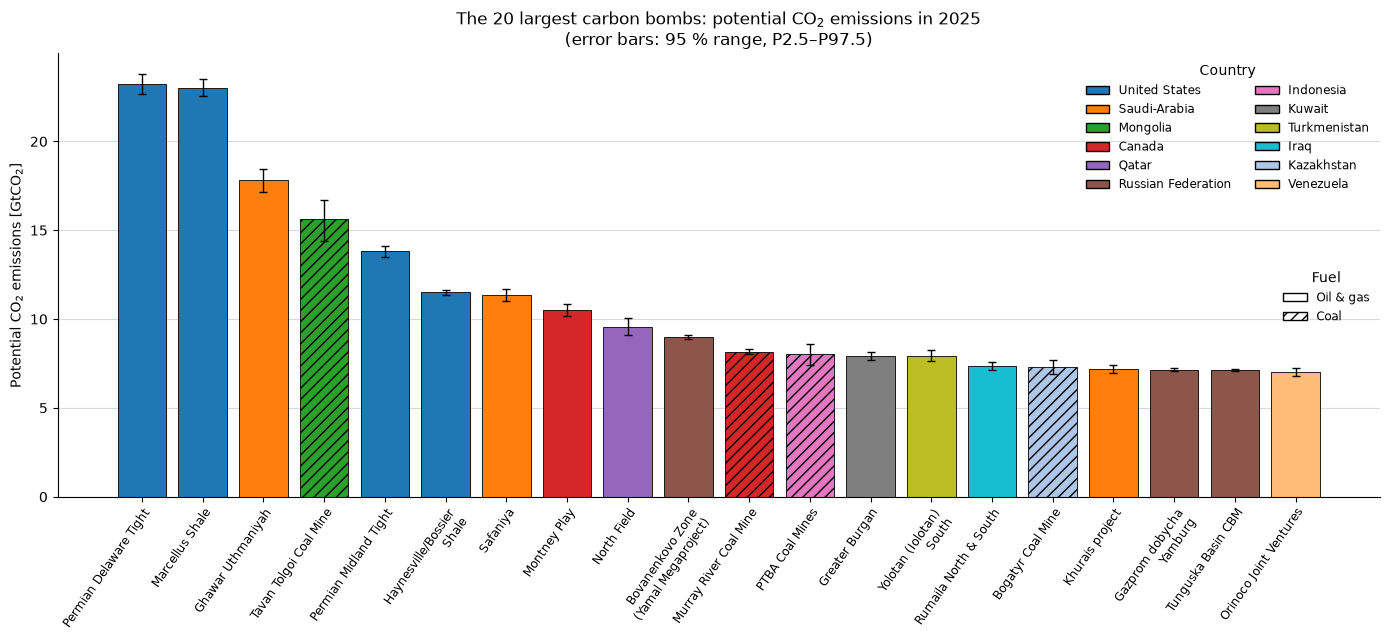

In [5]:
fig, ax = plot_top_carbon_bombs(ds_carbon_bombs, n_top=20,
                                save_path=FIG_DIR / "top20_carbon_bombs.png")
plt.show()

**What the figure shows.** The two largest carbon bombs, Permian Delaware Tight and Marcellus Shale, are both US shale oil and gas fields with about 23 GtCO₂ each. The United States has 4 projects in the top 20, Saudi Arabia and Russia 3 each. Only 4 of the 20 are coal mines (Mongolia, Canada, Indonesia, Kazakhstan); three of them have relatively wide error bars, which reflects the uncertainty of the coal emission factors (the only source of uncertainty in this dataset, since reserves are treated as fixed).